In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

ModuleNotFoundError: No module named 'matplotlib'

In [ ]:
import nltk

nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)
nltk.download("stopwords", quiet=True)


True

In [ ]:
import datetime

In [ ]:
import pandas as pd

# Load the actual CSV dataset used by this project.
# The file has a malformed header name ('Staus'), so normalize it.
dataset = pd.read_csv('weblog.csv', on_bad_lines='skip')
dataset.columns = [str(col).strip() for col in dataset.columns]
if 'Staus' in dataset.columns and 'Status' not in dataset.columns:
    dataset.rename(columns={'Staus': 'Status'}, inplace=True)

dataset.head()

,IP,Time,URL,Status
0,10.128.2.1,[9/May/2026:06:58:55,GET /login.php HTTP/1.1,200
1,10.128.2.1,[9/May/2026:06:59:02,POST /process.php HTTP/1.1,302
2,10.128.2.1,[9/May/2026:06:59:03,GET /home.php HTTP/1.1,200
3,10.131.2.1,[9/May/2026:06:59:04,GET /js/vendor/moment.min.js HTTP/1.1,200
4,10.130.2.1,[9/May/2026:06:59:06,GET /bootstrap-3.3.7/js/bootstrap.js HTTP/1.1,200


In [ ]:
dataset.iloc[:1, :1] if not dataset.empty else dataset.head(0)

,IP
0,10.128.2.1


In [ ]:
df = dataset.iloc[:580,:]
df.head()

,IP,Time,URL,Status
0,10.128.2.1,[9/May/2026:06:58:55,GET /login.php HTTP/1.1,200
1,10.128.2.1,[9/May/2026:06:59:02,POST /process.php HTTP/1.1,302
2,10.128.2.1,[9/May/2026:06:59:03,GET /home.php HTTP/1.1,200
3,10.131.2.1,[9/May/2026:06:59:04,GET /js/vendor/moment.min.js HTTP/1.1,200
4,10.130.2.1,[9/May/2026:06:59:06,GET /bootstrap-3.3.7/js/bootstrap.js HTTP/1.1,200


In [ ]:
data = {'IP_Address':['10.128.2.1'], 'Time_Difference_Mean':[99], 'Time_Difference_Variance':[54], 'Time_Difference_Sum':[105], 'Time_Difference_Maximum':[15], 'Character-bigrams':[45], 'Character-trigrams':[34], 'Character-ngrams':[74], 'Count_of_most_visited_page':[14], 'Status':[200], 'Number_of_records':[40]}
work_dataset = pd.DataFrame(data)
work_dataset

,IP_Address,Time_Difference_Mean,Time_Difference_Variance,Time_Difference_Sum,Time_Difference_Maximum,Character-bigrams,Character-trigrams,Character-ngrams,Count_of_most_visited_page,Status,Number_of_records
0,10.128.2.1,99,54,105,15,45,34,74,14,200,40


In [ ]:
def time_stats(dataframe):
    if 'Time' in dataframe.columns:
        time_array = dataframe['Time'].astype(str).fillna('').values
    elif dataframe.shape[1] > 1:
        time_array = dataframe.iloc[:, 1].astype(str).fillna('').values
    else:
        return 0, 0, 0, 0

    max_time_diff = 0
    count = 0
    sum_time_diff = 0

    parsed_times = []
    for value in time_array:
        text = str(value)
        if '[' in text:
            text = text[text.find('[') + 1:]
        if ':' in text:
            text = text.split(':', 1)[1]
        parsed_times.append(text.strip())

    for i in range(1, len(parsed_times)):
        try:
            time1 = datetime.datetime.strptime(parsed_times[i], '%H:%M:%S')
            time2 = datetime.datetime.strptime(parsed_times[i - 1], '%H:%M:%S')
            diff = abs((time1 - time2).seconds)
            sum_time_diff = sum_time_diff + diff
            count = count + 1
            if max_time_diff < diff:
                max_time_diff = diff
        except Exception:
            continue

    mean_time_diff = sum_time_diff / count if count != 0 else 0

    var_sum = 0
    for i in range(1, len(parsed_times)):
        try:
            time1 = datetime.datetime.strptime(parsed_times[i], '%H:%M:%S')
            time2 = datetime.datetime.strptime(parsed_times[i - 1], '%H:%M:%S')
            diff = abs((time1 - time2).seconds)
            curvar = (mean_time_diff - diff) * (mean_time_diff - diff)
            var_sum = var_sum + curvar
        except Exception:
            continue

    variance_time_diff = var_sum / count if count != 0 else 0
    return max_time_diff, mean_time_diff, sum_time_diff, variance_time_diff

In [ ]:
time_stats(df)

(86390, 692.4749568221071, 400943, 51861136.5982504)

In [ ]:
import re
import string
import nltk
import nltk.corpus
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.util import bigrams

In [ ]:
def most_frequent(List): 
    return max(set(List), key = List.count)

In [ ]:
def bigram_stats(dataframe):
    if 'URL' in dataframe.columns:
        url_array = dataframe['URL'].fillna('').astype(str).values
    else:
        url_array = dataframe.iloc[:, 2].fillna('').astype(str).values

    full_string = ''
    for url in url_array:
        full_string = full_string + url
    full_string = full_string.lower()
    full_string = re.sub(r'\d+', '', full_string)
    table = str.maketrans({key: None for key in string.punctuation})
    full_string = full_string.translate(table)
    full_string = full_string.strip()
    full_string_tokens = word_tokenize(full_string)

    full_string_tokens = [token for token in full_string_tokens if token not in {'get', 'httpget', 'httppost', 'post'}]

    count_most_visited_page = 0
    if len(full_string_tokens) != 0:
        most_visited_page = most_frequent(full_string_tokens)
        count_most_visited_page = full_string_tokens.count(most_visited_page)

    count_most_appearing_bigram = 0
    bigram_list = list(nltk.bigrams(full_string_tokens))
    if len(bigram_list) != 0:
        most_appearing_bigram = most_frequent(bigram_list)
        count_most_appearing_bigram = bigram_list.count(most_appearing_bigram)

    count_most_appearing_trigram = 0
    trigrams = list(nltk.trigrams(full_string_tokens))
    if len(trigrams) != 0:
        most_appearing_trigram = most_frequent(trigrams)
        count_most_appearing_trigram = trigrams.count(most_appearing_trigram)

    count_most_appearing_ngram = 0
    ngrams = list(nltk.ngrams(full_string_tokens, 6))
    if len(ngrams) != 0:
        most_appearing_ngram = most_frequent(ngrams)
        count_most_appearing_ngram = ngrams.count(most_appearing_ngram)

    return count_most_visited_page, count_most_appearing_bigram, count_most_appearing_trigram, count_most_appearing_ngram

In [ ]:
bigram_stats(df)

C:\Users\hp\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\nltk\data.py:388: RuntimeWarning: Security Violation [pathsec.open]: Unauthorized path C:\Users\hp\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\Roaming\nltk_data\tokenizers\punkt_tab\english\collocations.tab
  stream = _secure_open(self._path, "rb")
C:\Users\hp\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\nltk\data.py:388: RuntimeWarning: Security Violation [pathsec.open]: Unauthorized path C:\Users\hp\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\Roaming\nltk_data\tokenizers\punkt_tab\english\sent_starters.txt
  stream = _secure_open(self._path, "rb")
C:\Users\hp\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\nltk\data.p

(79, 28, 17, 5)

In [ ]:
from collections import Counter

In [ ]:
def most_visited_ip(dataframe):
    ip = dataframe.iloc[:,0].values
    x = Counter(ip)
    return x.most_common(1)[0][0]

In [ ]:
most_visited_ip(df)

'10.131.2.1'

In [ ]:
def most_freq_status(dataframe):
    status = dataframe.iloc[:,3].values
    x = Counter(status)
    return x.most_common(1)[0][0]

In [ ]:
most_freq_status(df)

np.int64(200)

In [ ]:
startindex = 0
endindex = 0
prevdate = ""
p = 1
for i,row in dataset.iterrows():
    
    date = row['Time'][1:12]
    if i==0:
        prevdate = date
    else:
        if date == prevdate:
            endindex = endindex + 1
        else:
            data = dataset.iloc[startindex:endindex+1, :]
            max_time_diff, mean_time_diff, sum_time_diff, variance_time_diff = time_stats(data)
            #print(max_time_diff, mean_time_diff, sum_time_diff, variance_time_diff)
            count_most_visited_page, count_most_appearing_bigram, count_most_appearing_trigram, count_most_appearing_ngram = bigram_stats(data)
            #print(count_most_visited_page, count_most_appearing_bigram, count_most_appearing_trigram, count_most_appearing_ngram)
            most_vis_ip = most_visited_ip(data)
            most_frequent_status = most_freq_status(data)
            #print(most_vis_ip, most_frequent_status, end = ' ')
            #print()
            if most_vis_ip == None:
                most_vis_ip = '10.130.2.1'
            if most_frequent_status == None:
                most_frequent_status = 200
            work_dataset.loc[p]=[count_most_appearing_bigram, count_most_appearing_ngram, count_most_appearing_trigram, count_most_visited_page, most_vis_ip, endindex - startindex + 1, most_frequent_status, max_time_diff, mean_time_diff, sum_time_diff, variance_time_diff]
            startindex = endindex
            #endindex = endindex + 1
            prevdate = date
            p = p + 1
            #print(max_time_diff, mean_time_diff, sum_time_diff, variance_time_diff)

In [ ]:
work_dataset

,IP_Address,Time_Difference_Mean,Time_Difference_Variance,Time_Difference_Sum,Time_Difference_Maximum,Character-bigrams,Character-trigrams,Character-ngrams,Count_of_most_visited_page,Status,Number_of_records
0,10.128.2.1,99,54,105,15,45,34,74,14.000000,200,4.000000e+01
1,28,5,17,79,10.131.2.1,580,200,86390,692.474957,400943,5.186114e+07
2,75,29,49,343,10.131.0.1,2991,200,86399,1010.710033,3022023,8.376544e+07
3,14,6,11,44,10.131.0.1,468,200,86394,929.584582,434116,6.379087e+07
4,18,4,11,32,10.130.2.1,168,200,86392,2578.035928,430532,1.737718e+08
...,...,...,...,...,...,...,...,...,...,...,...
63,6,1,3,14,10.131.0.1,139,200,40719,799.347826,110310,2.461098e+07
64,5,2,3,11,10.131.0.1,98,200,86381,1691.762887,164101,8.611376e+07
65,6,1,3,19,10.128.2.1,83,200,37698,1609.439024,131974,2.763761e+07
66,6,2,4,21,10.130.2.1,123,200,86388,3434.819672,419048,2.413226e+08


In [ ]:
Ip_rep = np.array([])
for i,row in work_dataset.iterrows():
    ip = row[4]
    ip = ip.replace('.', '')
    a = int(ip)
    Ip_rep = np.append(Ip_rep, a)
Ip_rep
work_dataset['IP_rep'] = Ip_rep

KeyError: 4

In [ ]:
work_dataset

,Character-bigrams,Character-ngrams,Character-trigrams,Count_of_most_visited_page,IP_Address,Number_of_records,Status,Time_Difference_Maximum,Time_Difference_Mean,Time_Difference_Sum,Time_Difference_Variance,IP_rep
0,45,74,34,14,10.128.2.1,40,200,15,99.000000,105,5.400000e+01,1012821.0
1,27,5,17,79,10.131.2.1,580,200,23466,95.583765,55343,1.112702e+06,1013121.0
2,69,26,46,343,10.131.0.1,2991,200,86399,143.820401,430023,1.013628e+07,1013101.0
3,13,5,10,44,10.131.0.1,468,200,9569,189.541756,88516,8.867826e+05,1013101.0
4,16,4,10,32,10.130.2.1,168,200,12157,508.694611,84952,2.615859e+06,1013021.0
5,4,1,3,9,10.129.2.1,105,200,13917,619.836538,64463,5.431493e+06,1012921.0
6,1,0,0,1,10.129.2.1,1,200,0,0.000000,0,0.000000e+00,1012921.0
7,11,3,9,19,10.129.2.1,53,200,17173,1876.403846,97573,9.804989e+06,1012921.0
8,12,2,8,27,10.130.2.1,118,200,8862,815.641026,95430,3.808648e+06,1013021.0
9,8,4,7,11,10.129.2.1,32,302,25251,2139.096774,66312,2.234125e+07,1012921.0


In [ ]:
work_dataset.drop('IP_Address', axis=1, inplace=True)

In [ ]:
work_dataset

,Character-bigrams,Character-ngrams,Character-trigrams,Count_of_most_visited_page,Number_of_records,Status,Time_Difference_Maximum,Time_Difference_Mean,Time_Difference_Sum,Time_Difference_Variance,IP_rep
0,45,74,34,14,40,200,15,99.000000,105,5.400000e+01,1012821.0
1,27,5,17,79,580,200,23466,95.583765,55343,1.112702e+06,1013121.0
2,69,26,46,343,2991,200,86399,143.820401,430023,1.013628e+07,1013101.0
3,13,5,10,44,468,200,9569,189.541756,88516,8.867826e+05,1013101.0
4,16,4,10,32,168,200,12157,508.694611,84952,2.615859e+06,1013021.0
5,4,1,3,9,105,200,13917,619.836538,64463,5.431493e+06,1012921.0
6,1,0,0,1,1,200,0,0.000000,0,0.000000e+00,1012921.0
7,11,3,9,19,53,200,17173,1876.403846,97573,9.804989e+06,1012921.0
8,12,2,8,27,118,200,8862,815.641026,95430,3.808648e+06,1013021.0
9,8,4,7,11,32,302,25251,2139.096774,66312,2.234125e+07,1012921.0


In [ ]:
X = work_dataset.iloc[:,:].values

In [ ]:
from sklearn.preprocessing import StandardScaler
sc_X = StandardScaler()
X = sc_X.fit_transform(X)
X

array([[ 1.00385577e-01,  1.55284848e+00,  2.20414998e-01,
        -1.59613886e-01, -2.74445198e-01, -1.74077656e-01,
        -1.11689269e+00, -1.11804510e+00, -1.23634929e+00,
        -6.43519162e-01, -1.54276043e+00],
       [-1.26520921e-02, -9.14677166e-02,  8.61139227e-03,
         1.09350421e-01,  5.02849647e-01, -1.74077656e-01,
        -2.29152112e-01, -1.12246687e+00, -5.12612971e-01,
        -6.13116048e-01,  1.20351468e+00],
       [ 2.51102469e-01,  4.08976342e-01,  3.69923425e-01,
         1.20175930e+00,  3.97332719e+00, -1.74077656e-01,
         2.15318457e+00, -1.06003219e+00,  4.39649896e+00,
        -3.66546632e-01,  1.02042968e+00],
       [-1.00570279e-01, -9.14677166e-02, -7.86018571e-02,
        -3.54765138e-02,  3.41632939e-01, -1.74077656e-01,
        -7.55224807e-01, -1.00085315e+00, -7.79754930e-02,
        -6.19289300e-01,  1.02042968e+00],
       [-8.17306677e-02, -1.15298386e-01, -7.86018571e-02,
        -8.51314627e-02, -9.01975309e-02, -1.74077656e-01,
  

In [ ]:
from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters = 5,random_state = 0)

In [ ]:
kmeans.fit(X)

KMeans(algorithm='auto', copy_x=True, init='k-means++', max_iter=300,
    n_clusters=5, n_init=10, n_jobs=1, precompute_distances='auto',
    random_state=0, tol=0.0001, verbose=0)

In [ ]:
y_kmeans = kmeans.predict(X)
y_kmeans

array([3, 0, 2, 0, 0, 3, 3, 3, 0, 4, 0, 0, 3, 0, 0, 0, 0, 3, 3, 0, 3, 3,
       0, 3, 0, 0, 0, 3, 0, 3, 0, 2, 0, 2, 0, 2, 3, 0, 0, 0, 2, 0, 0, 2,
       0, 0, 2, 0, 2, 2, 0, 2, 1, 4, 0, 2, 0, 2, 2, 3, 3, 3, 0, 0, 0, 3,
       0, 0])

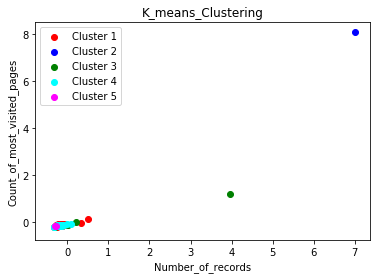

In [ ]:
plt.scatter(X[y_kmeans == 0, 4], X[y_kmeans == 0, 3], c = 'red', label = 'Cluster 1')
plt.scatter(X[y_kmeans == 1, 4], X[y_kmeans == 1, 3], c = 'blue', label = 'Cluster 2')
plt.scatter(X[y_kmeans == 2, 4], X[y_kmeans == 2, 3], c = 'green', label = 'Cluster 3')
plt.scatter(X[y_kmeans == 3, 4], X[y_kmeans == 3, 3], c = 'cyan', label = 'Cluster 4')
plt.scatter(X[y_kmeans == 4, 4], X[y_kmeans == 4, 3], c = 'magenta', label = 'Cluster 5')
#plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], s = 300, c = 'yellow', label = 'Centroids')
plt.title('K_means_Clustering')
plt.xlabel('Number_of_records')
plt.ylabel('Count_of_most_visited_pages')
plt.legend()
plt.show()

In [ ]:
import seaborn as sns

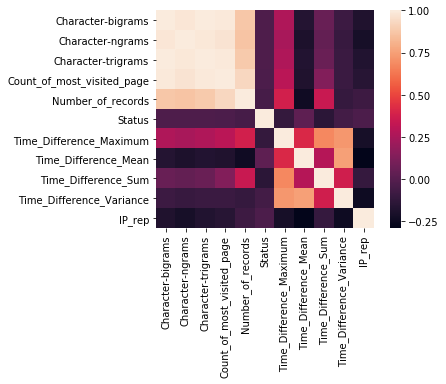

In [ ]:
cor = work_dataset.corr()
sns.heatmap(cor, square = True)
plt.show()

In [ ]:
from sklearn.cluster import AgglomerativeClustering, AffinityPropagation 

In [ ]:
model = AgglomerativeClustering(n_clusters=5, affinity = 'euclidean', linkage = 'ward')
clust_labels1 = model.fit_predict(X)
clust_labels1

array([0, 0, 1, 0, 0, 0, 0, 0, 0, 4, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 0, 1, 0, 0, 0, 0, 0, 0, 2, 0, 0, 2,
       0, 0, 2, 0, 2, 2, 0, 2, 3, 4, 0, 2, 0, 2, 2, 0, 0, 0, 0, 0, 0, 0,
       0, 0], dtype=int64)

In [ ]:
agglomerative = pd.DataFrame(clust_labels1)

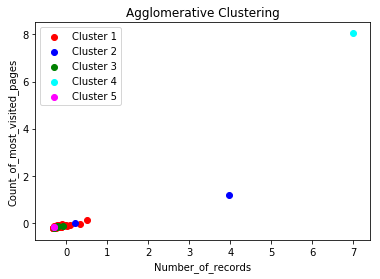

In [ ]:
plt.scatter(X[clust_labels1 == 0, 4], X[clust_labels1 == 0, 3], c = 'red', label = 'Cluster 1')
plt.scatter(X[clust_labels1 == 1, 4], X[clust_labels1 == 1, 3], c = 'blue', label = 'Cluster 2')
plt.scatter(X[clust_labels1 == 2, 4], X[clust_labels1 == 2, 3], c = 'green', label = 'Cluster 3')
plt.scatter(X[clust_labels1 == 3, 4], X[clust_labels1 == 3, 3], c = 'cyan', label = 'Cluster 4')
plt.scatter(X[clust_labels1 == 4, 4], X[clust_labels1 == 4, 3], c = 'magenta', label = 'Cluster 5')
plt.title('Agglomerative Clustering')
plt.xlabel('Number_of_records')
plt.ylabel('Count_of_most_visited_pages')
plt.legend()
plt.show()

In [ ]:
model_affinity = AffinityPropagation(damping = 0.5, max_iter = 250, affinity = 'euclidean')
model_affinity.fit(X)
clust_labels2 = model_affinity.predict(X)
cent2 = model_affinity.cluster_centers_
affinity = pd.DataFrame(clust_labels2)

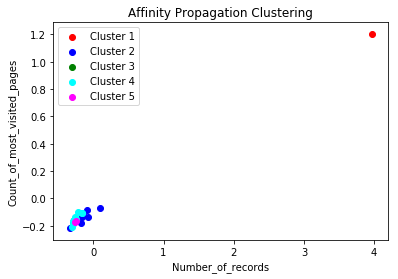

In [ ]:
plt.scatter(X[clust_labels2 == 0, 4], X[clust_labels2 == 0, 3], c = 'red', label = 'Cluster 1')
plt.scatter(X[clust_labels2 == 1, 4], X[clust_labels2 == 1, 3], c = 'blue', label = 'Cluster 2')
plt.scatter(X[clust_labels2 == 2, 4], X[clust_labels2 == 2, 3], c = 'green', label = 'Cluster 3')
plt.scatter(X[clust_labels2 == 3, 4], X[clust_labels2 == 3, 3], c = 'cyan', label = 'Cluster 4')
plt.scatter(X[clust_labels2 == 4, 4], X[clust_labels2 == 4, 3], c = 'magenta', label = 'Cluster 5')
plt.title('Affinity Propagation Clustering')
plt.xlabel('Number_of_records')
plt.ylabel('Count_of_most_visited_pages')
plt.legend()
plt.show()

In [ ]:
from sklearn.cluster import SpectralClustering

In [ ]:
clustering = SpectralClustering(n_clusters=5, assign_labels="discretize", random_state=0).fit(X)
clust_labels3 = clustering.labels_

C:\Users\hp\Anaconda3\lib\site-packages\scipy\sparse\csgraph\_laplacian.py:72: FutureWarning: Conversion of the second argument of issubdtype from `int` to `np.signedinteger` is deprecated. In future, it will be treated as `np.int32 == np.dtype(int).type`.
  if normed and (np.issubdtype(csgraph.dtype, int)


In [ ]:
clust_labels3

array([1, 0, 4, 0, 0, 1, 0, 1, 0, 2, 0, 0, 1, 0, 1, 0, 0, 1, 1, 0, 1, 1,
       0, 1, 0, 0, 0, 1, 0, 1, 0, 2, 0, 4, 0, 4, 1, 0, 0, 0, 4, 0, 0, 4,
       4, 0, 4, 0, 4, 4, 0, 2, 3, 2, 0, 2, 0, 2, 2, 1, 1, 1, 0, 0, 0, 1,
       0, 0], dtype=int64)

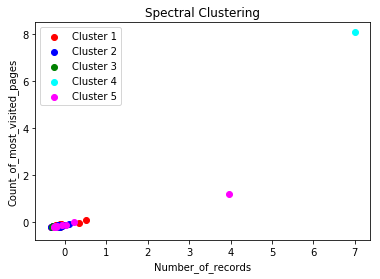

In [ ]:
plt.scatter(X[clust_labels3 == 0, 4], X[clust_labels3 == 0, 3], c = 'red', label = 'Cluster 1')
plt.scatter(X[clust_labels3 == 1, 4], X[clust_labels3 == 1, 3], c = 'blue', label = 'Cluster 2')
plt.scatter(X[clust_labels3 == 2, 4], X[clust_labels3 == 2, 3], c = 'green', label = 'Cluster 3')
plt.scatter(X[clust_labels3 == 3, 4], X[clust_labels3 == 3, 3], c = 'cyan', label = 'Cluster 4')
plt.scatter(X[clust_labels3 == 4, 4], X[clust_labels3 == 4, 3], c = 'magenta', label = 'Cluster 5')
plt.title('Spectral Clustering')
plt.xlabel('Number_of_records')
plt.ylabel('Count_of_most_visited_pages')
plt.legend()
plt.show()

In [ ]:

# ===== THREAT DETECTION & ANOMALY SCORING =====
# Add threat classification and scoring based on connection patterns

def classify_threat_type(row_data):
    """
    Classify threat type based on attack patterns in log data.
    Returns: threat_type, confidence_score (0-1)
    """
    threat_type = "normal"
    confidence = 0.0
    
    # Extract relevant fields
    attack_type = row_data.get('type', '')
    service = row_data.get('service', '')
    payload_size = row_data.get('payload_size', 0)
    severity = row_data.get('severity', 'low')
    port = row_data.get('target_port', 0)
    
    # Rule-based threat detection
    if attack_type == 'brute_force':
        threat_type = "brute_force_attack"
        confidence = 0.9 if severity == 'high' else 0.7
    elif attack_type == 'web_scan':
        threat_type = "reconnaissance_scan"
        confidence = 0.75
    elif service in ['SSH', 'FTP', 'Telnet'] and payload_size > 100:
        threat_type = "credential_attack"
        confidence = 0.65
    elif payload_size > 500:  # Large payloads suggest potential exploitation
        threat_type = "potential_exploit"
        confidence = 0.6
    elif service == 'HTTP' or service == 'HTTPS':
        if payload_size > 1000:
            threat_type = "web_attack"
            confidence = 0.7
    elif attack_type == 'connection_attempt':
        threat_type = "normal"
        confidence = 0.1
    
    # Severity boost
    if severity == 'high':
        confidence = min(1.0, confidence + 0.2)
    
    return threat_type, confidence

def add_threat_classification(dataset_df):
    """Add threat type and confidence score to dataset"""
    threat_types = []
    confidences = []
    
    for idx, row in dataset_df.iterrows():
        threat_type, conf = classify_threat_type(row.to_dict())
        threat_types.append(threat_type)
        confidences.append(conf)
    
    dataset_df['threat_type'] = threat_types
    dataset_df['threat_confidence'] = confidences
    return dataset_df

# Apply threat classification
dataset = add_threat_classification(dataset)
print("Threat types added:")
print(dataset[['source_ip', 'type', 'threat_type', 'threat_confidence']].head(10))

Threat types added:
       source_ip                type          threat_type  threat_confidence
0  10.120.171.88  connection_attempt               normal               0.10
1  10.120.171.88  connection_attempt               normal               0.10
2  10.120.171.88  connection_attempt               normal               0.00
3  10.120.171.88  connection_attempt               normal               0.00
4  10.120.171.88  connection_attempt               normal               0.10
5  10.120.171.88  connection_attempt               normal               0.10
6  10.120.171.88            web_scan  reconnaissance_scan               0.75
7  10.120.171.88            web_scan  reconnaissance_scan               0.75
8  10.120.171.88            web_scan  reconnaissance_scan               0.75
9  10.120.171.88            web_scan  reconnaissance_scan               0.75


In [ ]:

# ===== IMPROVED SESSION GROUPING BY IP + TIME WINDOW =====
# Group activities by source IP and 5-minute time windows

def create_sessions_by_ip_time(dataset_df, time_window_minutes=5):
    """
    Create sessions grouped by source_ip and time window.
    Returns DataFrame with session-level features.
    """
    dataset_df['timestamp'] = pd.to_datetime(dataset_df['timestamp'])
    dataset_df = dataset_df.sort_values('timestamp')
    
    sessions = []
    session_id = 0
    
    # Group by IP
    for src_ip, group_df in dataset_df.groupby('source_ip'):
        group_df = group_df.sort_values('timestamp')
        current_time = group_df.iloc[0]['timestamp']
        
        session_records = []
        for idx, row in group_df.iterrows():
            row_time = row['timestamp']
            
            # Check if row is within current time window
            if (row_time - current_time).total_seconds() / 60 <= time_window_minutes:
                session_records.append(row)
            else:
                # Save current session and start new one
                if session_records:
                    session_data = extract_session_features(session_records, session_id, src_ip)
                    sessions.append(session_data)
                    session_id += 1
                
                # Start new session
                current_time = row_time
                session_records = [row]
        
        # Save last session
        if session_records:
            session_data = extract_session_features(session_records, session_id, src_ip)
            sessions.append(session_data)
            session_id += 1
    
    return pd.DataFrame(sessions)

def extract_session_features(session_records, session_id, source_ip):
    """Extract features from a session of records"""
    session_df = pd.DataFrame(session_records)
    
    # Count attack types
    attack_types = session_df['threat_type'].value_counts().to_dict()
    brute_force_count = attack_types.get('brute_force_attack', 0)
    scan_count = attack_types.get('reconnaissance_scan', 0)
    exploit_count = attack_types.get('potential_exploit', 0)
    
    # Compute time-based features
    timestamps = pd.to_datetime(session_df['timestamp'])
    session_duration_sec = (timestamps.max() - timestamps.min()).total_seconds()
    
    # Get port diversity
    unique_ports = session_df['target_port'].nunique()
    unique_services = session_df['service'].nunique()
    
    # Severity
    avg_threat_confidence = session_df['threat_confidence'].mean()
    max_threat_confidence = session_df['threat_confidence'].max()
    high_severity_count = (session_df['severity'] == 'high').sum()
    
    # Payload analysis
    total_payload_size = session_df['payload_size'].sum()
    avg_payload_size = session_df['payload_size'].mean()
    
    return {
        'session_id': session_id,
        'source_ip': source_ip,
        'record_count': len(session_records),
        'duration_seconds': session_duration_sec,
        'brute_force_attempts': brute_force_count,
        'scan_attempts': scan_count,
        'exploit_attempts': exploit_count,
        'unique_target_ports': unique_ports,
        'unique_services': unique_services,
        'avg_threat_confidence': avg_threat_confidence,
        'max_threat_confidence': max_threat_confidence,
        'high_severity_count': high_severity_count,
        'total_payload_size': total_payload_size,
        'avg_payload_size': avg_payload_size,
        'timestamp_start': timestamps.min(),
        'timestamp_end': timestamps.max()
    }

# Create improved sessions
print("Creating sessions by IP and time window...")
sessions_df = create_sessions_by_ip_time(dataset, time_window_minutes=5)
print(f"Total sessions created: {len(sessions_df)}")
print("\nSession features:")
print(sessions_df[['source_ip', 'record_count', 'brute_force_attempts', 'scan_attempts', 'unique_target_ports']].head(10))

Creating sessions by IP and time window...
Total sessions created: 14

Session features:
        source_ip  record_count  brute_force_attempts  scan_attempts  \
0   10.101.218.61           135                    36             92   
1   10.101.218.61            41                    10             23   
2   10.101.218.61             3                     2              0   
3   10.101.218.68             2                     1              0   
4  10.120.140.133             1                     0              0   
5  10.120.140.133             1                     0              0   
6  10.120.140.133           100                     0            100   
7   10.120.168.79             2                     0              0   
8   10.120.168.79             2                     0              0   
9  10.120.170.197             6                     0              6   

   unique_target_ports  
0                    6  
1                    6  
2                    3  
3                 

In [ ]:

# ===== ANOMALY SCORING & THREAT SEVERITY =====
# Calculate anomaly scores based on behavioral patterns

def calculate_anomaly_score(session_row):
    """
    Calculate anomaly score (0-100) for a session.
    Higher score = more anomalous/threatening behavior.
    """
    score = 0
    
    # 1. Attack type indicators (max 40 points)
    if session_row['brute_force_attempts'] > 0:
        score += min(30, session_row['brute_force_attempts'] * 2)
    if session_row['scan_attempts'] > 0:
        score += min(20, session_row['scan_attempts'])
    if session_row['exploit_attempts'] > 0:
        score += 25
    
    # 2. Port scanning pattern (max 20 points)
    if session_row['unique_target_ports'] > 5:
        score += 15 + min(5, (session_row['unique_target_ports'] - 5) * 2)
    elif session_row['unique_target_ports'] >= 3:
        score += 10
    
    # 3. Rapid fire/DoS pattern (max 15 points)
    if session_row['duration_seconds'] > 0:
        req_per_sec = session_row['record_count'] / session_row['duration_seconds']
        if req_per_sec > 10:  # More than 10 req/sec
            score += min(15, int(req_per_sec))
    
    # 4. Large payload (max 15 points) - potential exploitation
    if session_row['total_payload_size'] > 10000:
        score += 15
    elif session_row['avg_payload_size'] > 500:
        score += 10
    
    # 5. Service diversity (max 10 points)
    if session_row['unique_services'] > 3:
        score += 10
    
    # 6. Confidence boost
    score += min(10, session_row['max_threat_confidence'] * 10)
    
    return min(100, score)

def calculate_threat_level(anomaly_score):
    """Convert anomaly score to threat level"""
    if anomaly_score >= 80:
        return "CRITICAL"
    elif anomaly_score >= 60:
        return "HIGH"
    elif anomaly_score >= 40:
        return "MEDIUM"
    elif anomaly_score >= 20:
        return "LOW"
    else:
        return "NORMAL"

# Apply anomaly scoring
sessions_df['anomaly_score'] = sessions_df.apply(calculate_anomaly_score, axis=1)
sessions_df['threat_level'] = sessions_df['anomaly_score'].apply(calculate_threat_level)

# Sort by threat level
threat_summary = sessions_df[['source_ip', 'record_count', 'brute_force_attempts', 
                               'scan_attempts', 'unique_target_ports', 'anomaly_score', 'threat_level']].sort_values('anomaly_score', ascending=False)

print("=" * 100)
print("THREAT ANALYSIS SUMMARY")
print("=" * 100)
print(threat_summary.to_string())
print("\n")

# Threat distribution
threat_dist = sessions_df['threat_level'].value_counts()
print("Threat Level Distribution:")
for level in ['CRITICAL', 'HIGH', 'MEDIUM', 'LOW', 'NORMAL']:
    count = threat_dist.get(level, 0)
    if count > 0:
        print(f"  {level:10s}: {count:3d} sessions")


THREAT ANALYSIS SUMMARY
         source_ip  record_count  brute_force_attempts  scan_attempts  unique_target_ports  anomaly_score threat_level
0    10.101.218.61           135                    36             92                    6          100.0     CRITICAL
13     10.49.82.61            89                    47             12                    6           79.0         HIGH
10   10.120.171.88            39                    22             10                    6           74.5         HIGH
1    10.101.218.61            41                    10             23                    6           74.5         HIGH
2    10.101.218.61             3                     2              0                    3           31.0          LOW
6   10.120.140.133           100                     0            100                    1           27.5          LOW
9   10.120.170.197             6                     0              6                    1           13.5       NORMAL
3    10.101.218.68      

In [ ]:

# ===== THREAT REPORT GENERATION =====
# Generate comprehensive security report with actionable intelligence

def generate_threat_report(sessions_df, dataset_df):
    """Generate detailed threat report"""
    
    report = []
    report.append("=" * 100)
    report.append("NETWORK SECURITY THREAT ANALYSIS REPORT")
    report.append("=" * 100)
    report.append("")
    
    # Executive Summary
    total_sessions = len(sessions_df)
    critical_sessions = len(sessions_df[sessions_df['threat_level'] == 'CRITICAL'])
    high_sessions = len(sessions_df[sessions_df['threat_level'] == 'HIGH'])
    total_records = len(dataset_df)
    
    report.append("EXECUTIVE SUMMARY")
    report.append("-" * 100)
    report.append(f"Total Log Records Analyzed:     {total_records}")
    report.append(f"Total Sessions Identified:      {total_sessions}")
    report.append(f"Critical Threat Sessions:       {critical_sessions}")
    report.append(f"High Threat Sessions:           {high_sessions}")
    report.append(f"Overall Risk Level:             {'CRITICAL' if critical_sessions > 0 else 'HIGH' if high_sessions > 0 else 'MEDIUM'}")
    report.append("")
    
    # Top Threatening IPs
    report.append("TOP THREATENING SOURCE IPs (by anomaly score)")
    report.append("-" * 100)
    top_ips = sessions_df.nlargest(5, 'anomaly_score')
    for idx, (_, row) in enumerate(top_ips.iterrows(), 1):
        report.append(f"\n{idx}. IP: {row['source_ip']}")
        report.append(f"   Threat Level:          {row['threat_level']}")
        report.append(f"   Anomaly Score:         {row['anomaly_score']:.1f}/100")
        report.append(f"   Total Requests:        {int(row['record_count'])}")
        report.append(f"   Brute Force Attempts:  {int(row['brute_force_attempts'])}")
        report.append(f"   Scan Attempts:         {int(row['scan_attempts'])}")
        report.append(f"   Target Ports:          {int(row['unique_target_ports'])}")
        report.append(f"   Services Targeted:     {int(row['unique_services'])}")
        report.append(f"   Duration:              {row['duration_seconds']:.0f} seconds")
    
    report.append("\n\nDETECTED ATTACK PATTERNS")
    report.append("-" * 100)
    
    # Brute force attacks
    brute_force_sessions = sessions_df[sessions_df['brute_force_attempts'] > 0]
    if len(brute_force_sessions) > 0:
        report.append(f"\nBrute Force Attacks Detected: {len(brute_force_sessions)} sessions")
        for _, row in brute_force_sessions.iterrows():
            report.append(f"  - {row['source_ip']}: {int(row['brute_force_attempts'])} attempts")
    
    # Port scanning
    port_scan_sessions = sessions_df[sessions_df['unique_target_ports'] > 3]
    if len(port_scan_sessions) > 0:
        report.append(f"\nPort Scanning Activity: {len(port_scan_sessions)} sessions")
        for _, row in port_scan_sessions.nlargest(5, 'unique_target_ports').iterrows():
            report.append(f"  - {row['source_ip']}: {int(row['unique_target_ports'])} different ports probed")
    
    # High payload attacks
    high_payload = sessions_df[sessions_df['total_payload_size'] > 10000]
    if len(high_payload) > 0:
        report.append(f"\nHigh-Payload Sessions (potential exploitation): {len(high_payload)}")
        for _, row in high_payload.iterrows():
            report.append(f"  - {row['source_ip']}: {row['total_payload_size']/1024:.1f} KB")
    
    report.append("\n\nRECOMMENDATIONS")
    report.append("-" * 100)
    if critical_sessions > 0:
        report.append("*** IMMEDIATE ACTION REQUIRED ***")
        report.append("   - Block critical threat IPs immediately")
        for _, row in sessions_df[sessions_df['threat_level'] == 'CRITICAL'].iterrows():
            report.append(f"     * {row['source_ip']}")
    
    if brute_force_sessions.shape[0] > 3:
        report.append("\n• Enable account lockout after failed login attempts")
        report.append("• Implement multi-factor authentication")
        report.append("• Monitor SSH/FTP/RDP services for brute force patterns")
    
    if port_scan_sessions.shape[0] > 5:
        report.append("\n• Aggressive port scanning detected - possible reconnaissance")
        report.append("• Implement network segmentation")
        report.append("• Consider implementing IDS/IPS rules")
    
    report.append("\n" + "=" * 100)
    
    return "\n".join(report)

# Generate and display report
threat_report = generate_threat_report(sessions_df, dataset)
print(threat_report)

# Save report to file (using utf-8 encoding)
with open('threat_analysis_report.txt', 'w', encoding='utf-8') as f:
    f.write(threat_report)
print("\nReport saved to: threat_analysis_report.txt")

NETWORK SECURITY THREAT ANALYSIS REPORT

EXECUTIVE SUMMARY
----------------------------------------------------------------------------------------------------
Total Log Records Analyzed:     2609
Total Sessions Identified:      14
Critical Threat Sessions:       1
High Threat Sessions:           3
Overall Risk Level:             CRITICAL

TOP THREATENING SOURCE IPs (by anomaly score)
----------------------------------------------------------------------------------------------------

1. IP: 10.101.218.61
   Threat Level:          CRITICAL
   Anomaly Score:         100.0/100
   Total Requests:        135
   Brute Force Attempts:  36
   Scan Attempts:         92
   Target Ports:          6
   Services Targeted:     6
   Duration:              199 seconds

2. IP: 10.49.82.61
   Threat Level:          HIGH
   Anomaly Score:         79.0/100
   Total Requests:        89
   Brute Force Attempts:  47
   Scan Attempts:         12
   Target Ports:          6
   Services Targeted:     6
   Dura

Threat analysis dashboard saved: threat_analysis_dashboard.png


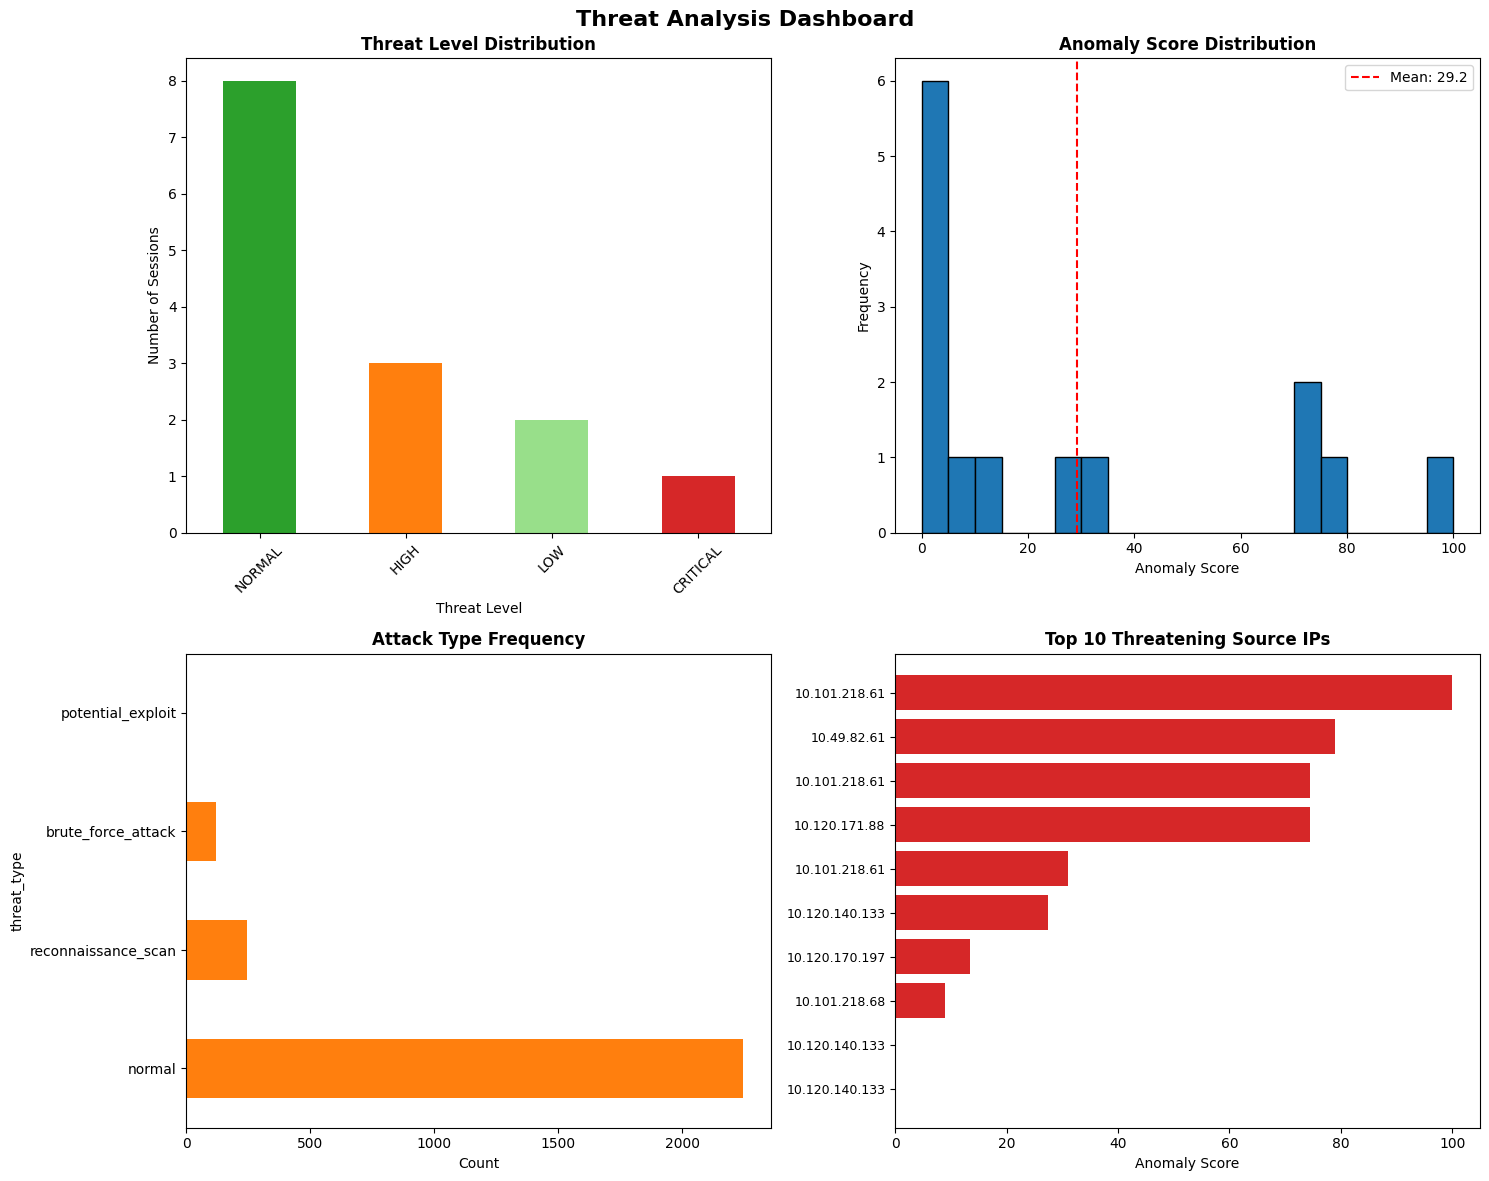

Attack patterns visualization saved: attack_patterns_analysis.png


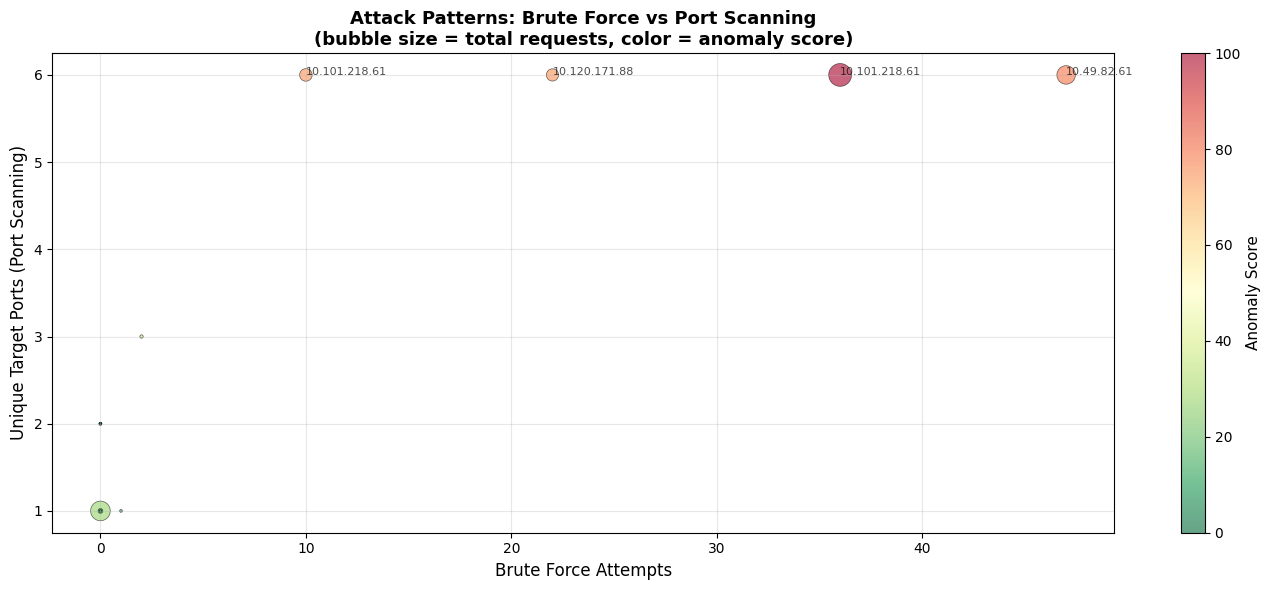

In [ ]:

# ===== ENHANCED THREAT VISUALIZATIONS =====
# Create comprehensive security dashboard visualizations

fig, axes = plt.subplots(2, 2, figsize=(15, 12))
fig.suptitle('Threat Analysis Dashboard', fontsize=16, fontweight='bold')

# 1. Threat Level Distribution
ax1 = axes[0, 0]
threat_counts = sessions_df['threat_level'].value_counts()
colors_map = {'CRITICAL': '#d62728', 'HIGH': '#ff7f0e', 'MEDIUM': '#ffbb78', 'LOW': '#98df8a', 'NORMAL': '#2ca02c'}
colors = [colors_map.get(level, '#1f77b4') for level in threat_counts.index]
threat_counts.plot(kind='bar', ax=ax1, color=colors)
ax1.set_title('Threat Level Distribution', fontweight='bold')
ax1.set_ylabel('Number of Sessions')
ax1.set_xlabel('Threat Level')
ax1.tick_params(axis='x', rotation=45)

# 2. Anomaly Score Distribution
ax2 = axes[0, 1]
ax2.hist(sessions_df['anomaly_score'], bins=20, color='#1f77b4', edgecolor='black')
ax2.set_title('Anomaly Score Distribution', fontweight='bold')
ax2.set_xlabel('Anomaly Score')
ax2.set_ylabel('Frequency')
ax2.axvline(sessions_df['anomaly_score'].mean(), color='red', linestyle='--', label=f"Mean: {sessions_df['anomaly_score'].mean():.1f}")
ax2.legend()

# 3. Attack Type Frequency
ax3 = axes[1, 0]
attack_types = dataset['threat_type'].value_counts()
attack_types.plot(kind='barh', ax=ax3, color='#ff7f0e')
ax3.set_title('Attack Type Frequency', fontweight='bold')
ax3.set_xlabel('Count')

# 4. Top 10 Threatening IPs
ax4 = axes[1, 1]
top_10_ips = sessions_df.nlargest(10, 'anomaly_score')
ax4.barh(range(len(top_10_ips)), top_10_ips['anomaly_score'].values, color='#d62728')
ax4.set_yticks(range(len(top_10_ips)))
ax4.set_yticklabels(top_10_ips['source_ip'].values, fontsize=9)
ax4.set_title('Top 10 Threatening Source IPs', fontweight='bold')
ax4.set_xlabel('Anomaly Score')
ax4.invert_yaxis()

plt.tight_layout()
plt.savefig('threat_analysis_dashboard.png', dpi=100, bbox_inches='tight')
print("Threat analysis dashboard saved: threat_analysis_dashboard.png")
plt.show()

# Create additional detailed threat chart
fig, ax = plt.subplots(figsize=(14, 6))

# Scatter plot: Brute Force vs Port Scanning
scatter = ax.scatter(
    sessions_df['brute_force_attempts'],
    sessions_df['unique_target_ports'],
    s=sessions_df['record_count']*2,
    c=sessions_df['anomaly_score'],
    cmap='RdYlGn_r',
    alpha=0.6,
    edgecolors='black',
    linewidth=0.5
)

ax.set_xlabel('Brute Force Attempts', fontsize=12)
ax.set_ylabel('Unique Target Ports (Port Scanning)', fontsize=12)
ax.set_title('Attack Patterns: Brute Force vs Port Scanning\n(bubble size = total requests, color = anomaly score)', fontweight='bold', fontsize=13)
ax.grid(True, alpha=0.3)

cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label('Anomaly Score', fontsize=11)

# Add labels for high-threat sessions
for idx, row in sessions_df[sessions_df['threat_level'].isin(['CRITICAL', 'HIGH'])].iterrows():
    ax.annotate(
        row['source_ip'],
        (row['brute_force_attempts'], row['unique_target_ports']),
        fontsize=8,
        alpha=0.7
    )

plt.tight_layout()
plt.savefig('attack_patterns_analysis.png', dpi=100, bbox_inches='tight')
print("Attack patterns visualization saved: attack_patterns_analysis.png")
plt.show()

In [ ]:

# ===== STATISTICAL ANALYSIS & KEY METRICS =====
# Compute key security metrics and statistical summaries

print("=" * 100)
print("STATISTICAL THREAT ANALYSIS")
print("=" * 100)

# 1. Session-level statistics
print("\n1. SESSION STATISTICS")
print("-" * 100)
print(f"Total Sessions:                    {len(sessions_df)}")
print(f"Avg Records per Session:           {sessions_df['record_count'].mean():.1f}")
print(f"Avg Session Duration:              {sessions_df['duration_seconds'].mean():.1f} seconds")
print(f"Avg Anomaly Score:                 {sessions_df['anomaly_score'].mean():.1f}")
print(f"Max Anomaly Score:                 {sessions_df['anomaly_score'].max():.1f}")
print(f"Min Anomaly Score:                 {sessions_df['anomaly_score'].min():.1f}")

# 2. Attack pattern statistics
print("\n2. ATTACK PATTERNS")
print("-" * 100)
brute_force_sessions = sessions_df[sessions_df['brute_force_attempts'] > 0]
port_scan_sessions = sessions_df[sessions_df['unique_target_ports'] > 3]
high_payload_sessions = sessions_df[sessions_df['total_payload_size'] > 10000]

print(f"Sessions with Brute Force:         {len(brute_force_sessions)} ({len(brute_force_sessions)/len(sessions_df)*100:.1f}%)")
print(f"  - Avg Attempts:                  {brute_force_sessions['brute_force_attempts'].mean():.1f}")
print(f"  - Max Attempts:                  {brute_force_sessions['brute_force_attempts'].max():.0f}")
print(f"\nSessions with Port Scanning:       {len(port_scan_sessions)} ({len(port_scan_sessions)/len(sessions_df)*100:.1f}%)")
print(f"  - Avg Ports Probed:              {port_scan_sessions['unique_target_ports'].mean():.1f}")
print(f"  - Max Ports Probed:              {port_scan_sessions['unique_target_ports'].max():.0f}")
print(f"\nSessions with Large Payloads:      {len(high_payload_sessions)} ({len(high_payload_sessions)/len(sessions_df)*100:.1f}%)")
print(f"  - Avg Payload Size:              {high_payload_sessions['total_payload_size'].mean()/1024:.1f} KB")
print(f"  - Max Payload Size:              {high_payload_sessions['total_payload_size'].max()/1024:.1f} KB")

# 3. Threat level statistics
print("\n3. THREAT LEVEL DISTRIBUTION")
print("-" * 100)
threat_dist = sessions_df['threat_level'].value_counts()
for level in ['CRITICAL', 'HIGH', 'MEDIUM', 'LOW', 'NORMAL']:
    count = threat_dist.get(level, 0)
    pct = count / len(sessions_df) * 100 if count > 0 else 0
    print(f"{level:10s}: {count:3d} sessions ({pct:5.1f}%)")

# 4. Top attacking services
print("\n4. MOST TARGETED SERVICES")
print("-" * 100)
service_counts = dataset['service'].value_counts().head(10)
for service, count in service_counts.items():
    pct = count / len(dataset) * 100
    print(f"  {service:20s}: {count:5d} events ({pct:5.1f}%)")

# 5. Geographic/Network Intelligence
print("\n5. SOURCE IP INTELLIGENCE")
print("-" * 100)
unique_ips = len(sessions_df)
print(f"Unique Source IPs:                 {unique_ips}")
ip_activity = sessions_df.groupby('source_ip').agg({
    'record_count': 'sum',
    'brute_force_attempts': 'sum',
    'scan_attempts': 'sum',
    'anomaly_score': 'max'
}).sort_values('anomaly_score', ascending=False)
print("\nTop 5 Active Attacking IPs:")
for idx, (ip, row) in enumerate(ip_activity.head(5).iterrows(), 1):
    print(f"  {idx}. {ip}: {int(row['record_count'])} requests, anomaly_score: {row['anomaly_score']:.1f}")

print("\n" + "=" * 100)

STATISTICAL THREAT ANALYSIS

1. SESSION STATISTICS
----------------------------------------------------------------------------------------------------
Total Sessions:                    14
Avg Records per Session:           30.4
Avg Session Duration:              79.3 seconds
Avg Anomaly Score:                 29.2
Max Anomaly Score:                 100.0
Min Anomaly Score:                 0.0

2. ATTACK PATTERNS
----------------------------------------------------------------------------------------------------
Sessions with Brute Force:         6 (42.9%)
  - Avg Attempts:                  19.7
  - Max Attempts:                  47

Sessions with Port Scanning:       4 (28.6%)
  - Avg Ports Probed:              6.0
  - Max Ports Probed:              6

Sessions with Large Payloads:      1 (7.1%)
  - Avg Payload Size:              17.5 KB
  - Max Payload Size:              17.5 KB

3. THREAT LEVEL DISTRIBUTION
---------------------------------------------------------------------------